# Smart Agriculture: Exploratory Data Analysis (EDA)
**Project**: Smart Agriculture Prediction System with MLOps  
**Domain**: B.Tech AI & Data Science  
**Objective**: Explore the crop recommendation dataset, analyze soil nutrient requirements (N, P, K) and environmental conditions (temperature, humidity, pH, rainfall), and identify feature correlations across 22 crop categories.


## 1. Import Required Libraries

In [3]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling configuration
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11


## 2. Load Dataset

In [5]:
# Resolve dataset path (supports execution from root or notebooks/ directory)
possible_paths = [
    Path('data/raw/crop_recommendation.csv'),
    Path('../data/raw/crop_recommendation.csv'),
]

data_path = next((p for p in possible_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError('Could not locate data/raw/crop_recommendation.csv')

df = pd.read_csv(data_path)
print(f'Successfully loaded dataset from: {data_path}')
print(df.head())


Successfully loaded dataset from: data/raw/crop_recommendation.csv
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice


## 3. Data Integrity and Structure Check

In [7]:
print('=== Dataset Dimensions ===')
print(f'Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}')

print('\n=== Column Names & Data Types ===')
print(df.dtypes)

print('\n=== Missing Values Check ===')
print(df.isnull().sum())

print('\n=== Duplicate Rows Check ===')
print(f'Duplicate rows: {df.duplicated().sum()}')


=== Dataset Dimensions ===
Total Rows: 2200, Total Columns: 8

=== Column Names & Data Types ===
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
dtype: object

=== Missing Values Check ===
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

=== Duplicate Rows Check ===
Duplicate rows: 0


## 4. Descriptive Statistics

In [9]:
stats = df.describe().T
print(stats)


              count        mean        std  ...        50%         75%         max
N            2200.0   50.551818  36.917334  ...  37.000000   84.250000  140.000000
P            2200.0   53.362727  32.985883  ...  51.000000   68.000000  145.000000
K            2200.0   48.149091  50.647931  ...  32.000000   49.000000  205.000000
temperature  2200.0   25.616244   5.063749  ...  25.598693   28.561654   43.675493
humidity     2200.0   71.481779  22.263812  ...  80.473146   89.948771   99.981876
ph           2200.0    6.469480   0.773938  ...   6.425045    6.923643    9.935091
rainfall     2200.0  103.463655  54.958389  ...  94.867624  124.267508  298.560117

[7 rows x 8 columns]


## 5. Crop Class Distribution

Total unique crops: 22
Samples per crop class:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


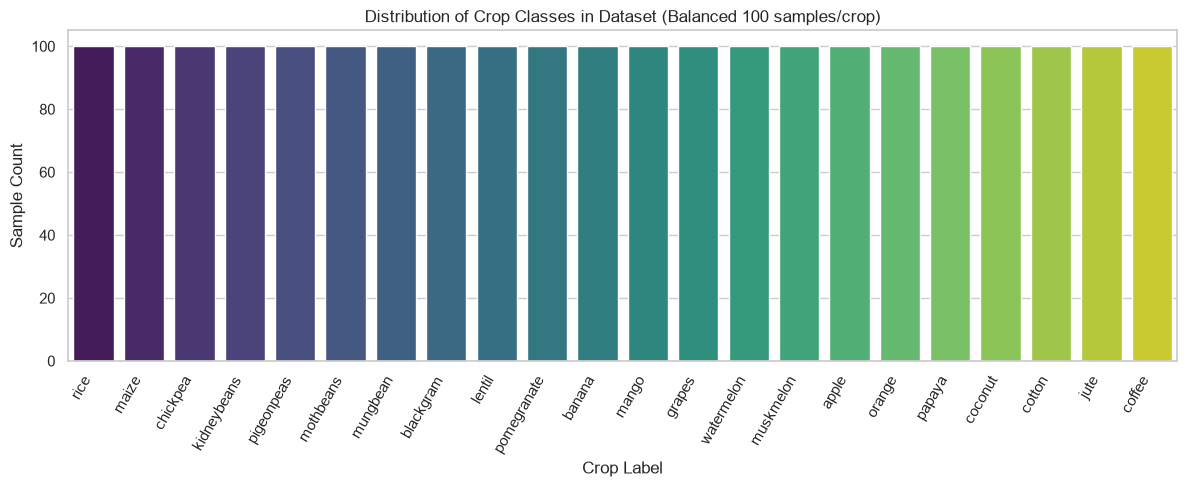

In [11]:
class_counts = df['label'].value_counts()
print(f'Total unique crops: {len(class_counts)}')
print('Samples per crop class:')
print(class_counts)

# Visualizing class distribution
plt.figure(figsize=(12, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette='viridis', legend=False)
plt.xticks(rotation=60, ha='right')
plt.title('Distribution of Crop Classes in Dataset (Balanced 100 samples/crop)')
plt.xlabel('Crop Label')
plt.ylabel('Sample Count')
plt.tight_layout()
plt.show()


## 6. Feature Distributions (Soil Nutrients & Climate Variables)

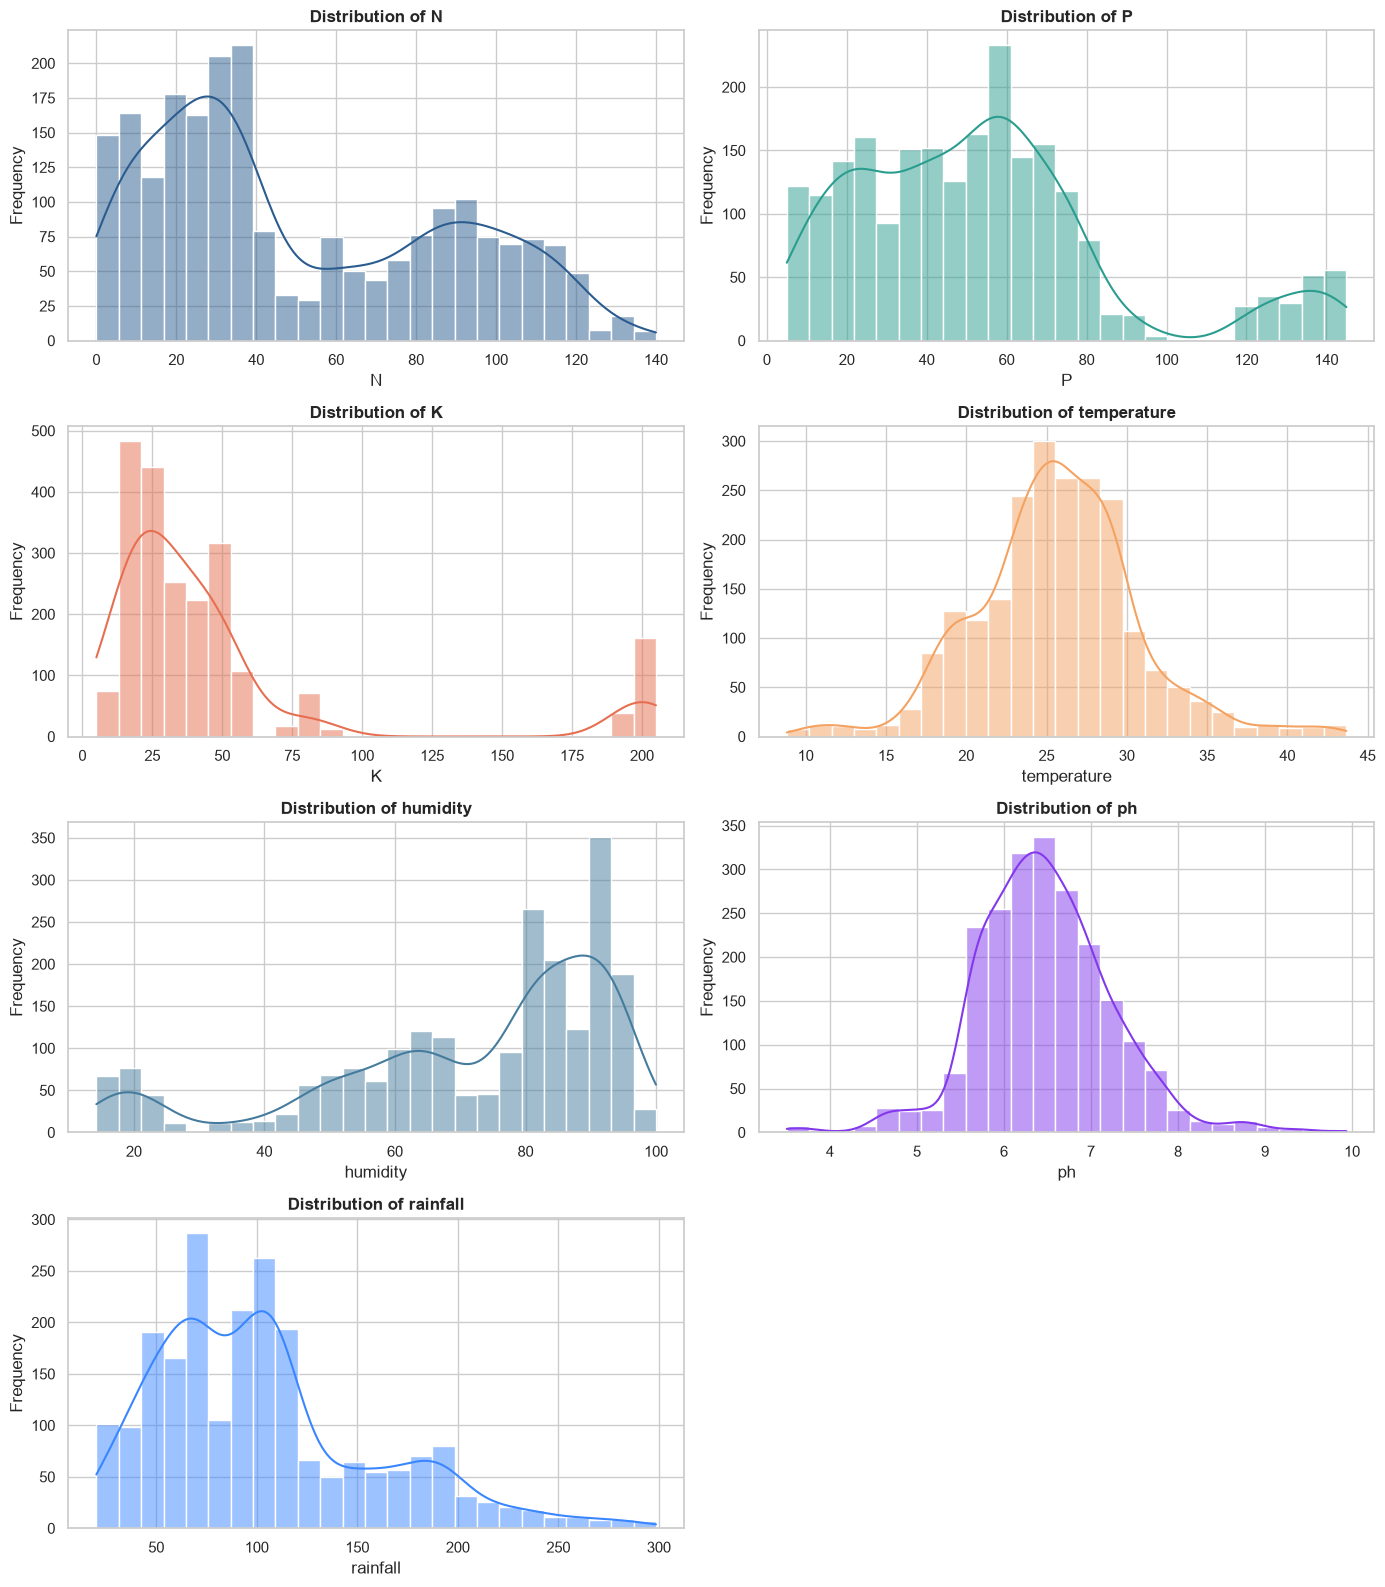

In [13]:
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
colors = ['#2b5c8f', '#2a9d8f', '#e76f51', '#f4a261', '#457b9d', '#8338ec', '#3a86ff']

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], color=colors[i], bins=25)
    axes[i].set_title(f'Distribution of {col}', fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

# Hide unused 8th subplot
axes[-1].set_visible(False)
plt.tight_layout()
plt.show()


## 7. Correlation Analysis

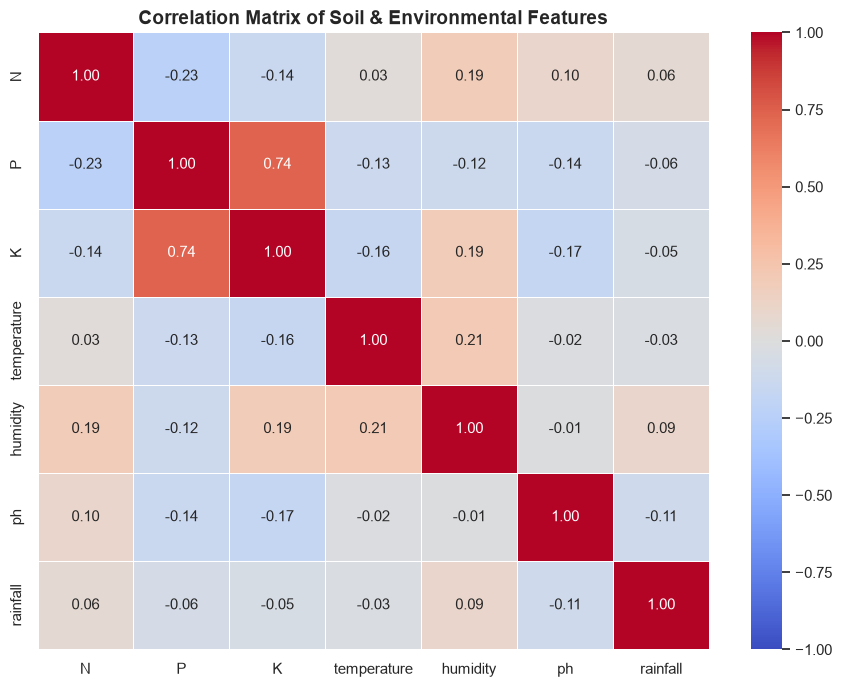

In [15]:
plt.figure(figsize=(9, 7))
numeric_df = df[features]
correlation_matrix = numeric_df.corr()

sns.heatmap(
    correlation_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.2f', 
    linewidths=0.5, 
    vmin=-1, 
    vmax=1
)
plt.title('Correlation Matrix of Soil & Environmental Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 8. Crop vs. Environmental & Soil Requirements

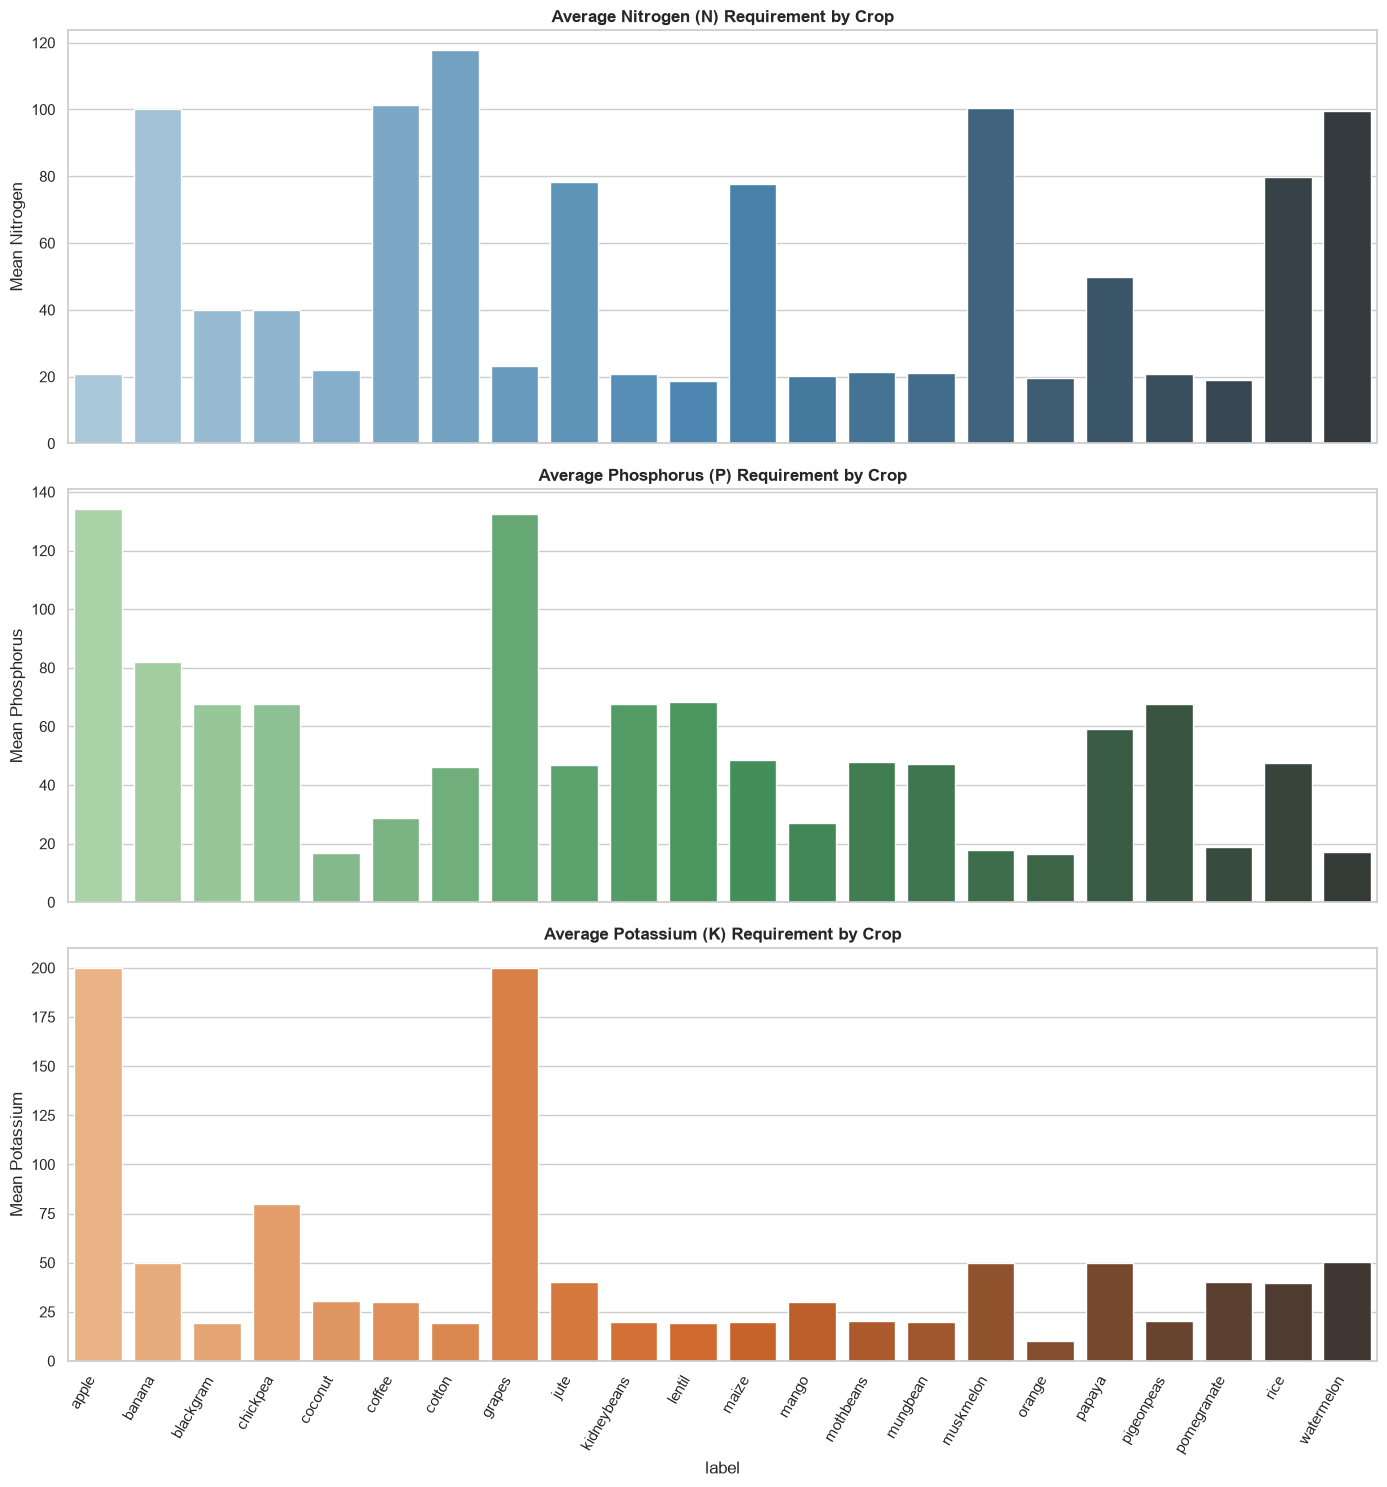

In [17]:
# Compare average N, P, K requirements across crop types
crop_nutrients = df.groupby('label')[['N', 'P', 'K']].mean().reset_index()

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(14, 15), sharex=True)

sns.barplot(data=crop_nutrients, x='label', y='N', ax=axes[0], hue='label', palette='Blues_d', legend=False)
axes[0].set_title('Average Nitrogen (N) Requirement by Crop', fontweight='bold')
axes[0].set_ylabel('Mean Nitrogen')

sns.barplot(data=crop_nutrients, x='label', y='P', ax=axes[1], hue='label', palette='Greens_d', legend=False)
axes[1].set_title('Average Phosphorus (P) Requirement by Crop', fontweight='bold')
axes[1].set_ylabel('Mean Phosphorus')

sns.barplot(data=crop_nutrients, x='label', y='K', ax=axes[2], hue='label', palette='Oranges_d', legend=False)
axes[2].set_title('Average Potassium (K) Requirement by Crop', fontweight='bold')
axes[2].set_ylabel('Mean Potassium')
axes[2].set_xticklabels(crop_nutrients['label'], rotation=60, ha='right')

plt.tight_layout()
plt.show()


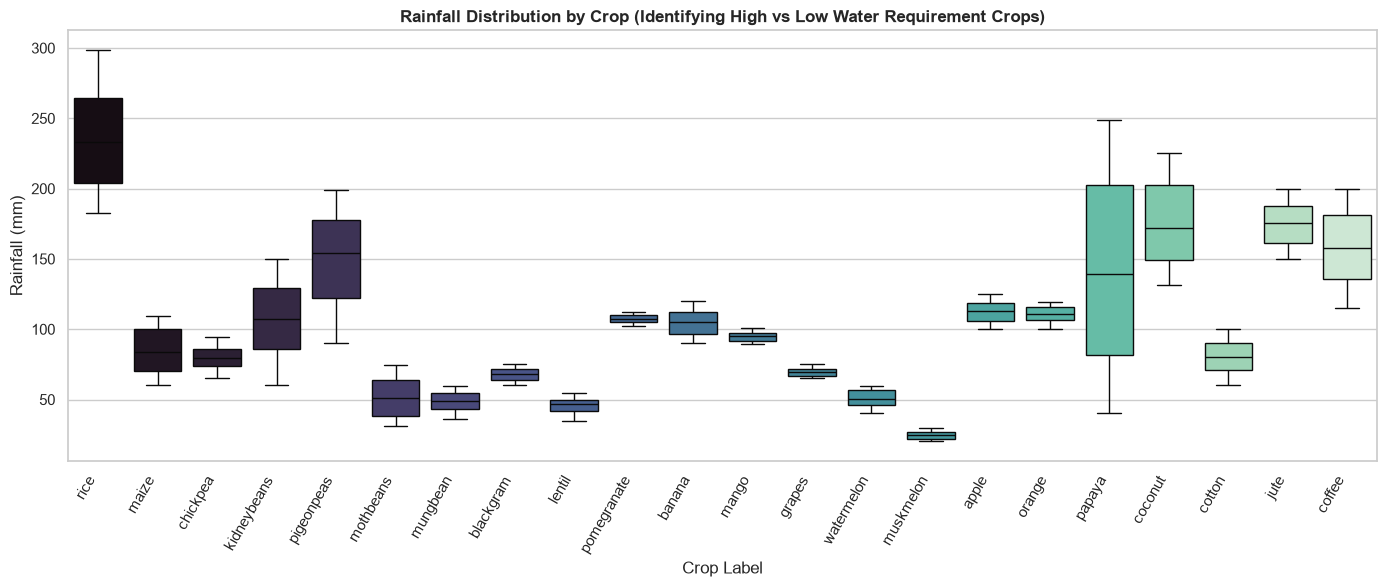

In [18]:
# Compare Rainfall distribution across all crops
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x='label', y='rainfall', hue='label', palette='mako', legend=False)
plt.xticks(rotation=60, ha='right')
plt.title('Rainfall Distribution by Crop (Identifying High vs Low Water Requirement Crops)', fontweight='bold')
plt.xlabel('Crop Label')
plt.ylabel('Rainfall (mm)')
plt.tight_layout()
plt.show()


## 9. Key Takeaways & Observations
1. **Balanced Classes**: Exactly 100 samples per crop across 22 classes (no class imbalance).
2. **Data Cleanliness**: 0 null values and 0 duplicate rows across all 2,200 records.
3. **Distinct Crop Profiles**:
   - **High Nitrogen**: Cotton, Maize, Rice, Watermelon.
   - **High Phosphorus & Potassium**: Apple, Grapes require extremely high P & K (>100-140) compared to all other crops.
   - **High Rainfall**: Rice (>200mm), Papaya, Coconut require heavy rainfall.
   - **Low Moisture / Arid**: Mothbeans, Mungbean, Lentil thrive in low rainfall (<60mm).
4. **Multiclass Separability**: Clear separation across soil and climate dimensions indicates strong suitability for classification algorithms (Logistic Regression, Decision Trees, Random Forests).
